# **Main Code**

**Importing necessary libraries**

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.regime_switching.markov_switching import MarkovSwitching

**Dataset utilised in paper: to check results**

In [ ]:
#data_path = "/Users/utente/Desktop/Thesis/Thesis/src/data.xlsx"
#data = pd.read_excel(data_path, header=None)

**Read datasets**

In [8]:
pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 941 kB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [9]:
file_path = "/Users/utente/Desktop/Thesis/Thesis/src/Thesis_Dataset.xlsx"
dataset = pd.read_excel(file_path)

rf_path = "/Users/utente/Desktop/Thesis/Thesis/src/Rf.xlsx"
rf = pd.read_excel(rf_path)

**Filter datasets to include data from July 1969 onward**

In [10]:
# Filter the dataset for all rows where the Date is greater than or equal to July 1969
dataset = dataset[dataset['Date'] >= '1969-07']
rf = rf[rf['Date'] >= '1969-07']
rf = rf.drop(rf.index[-1]) #exclude last observation to align the datasets
rf = rf.iloc[:, [0, -1]] #keep risk-free rate column as it is the information we are interested in
print(dataset.shape)
print(rf.shape)

(663, 50)
(663, 2)


Missing data are indicated by -99.99 or -999.

Check presence in our data.

In [11]:
# Identify missing data values (-99.99 and -999) in the dataset
missing_data_counts = (dataset == -99.99).sum() + (dataset == -999).sum()

# Display columns with missing data counts
missing_data_present = missing_data_counts[missing_data_counts > 0]

# If you want to check the total number of such missing values in the dataset:
total_missing_data = missing_data_counts.sum()
print(f"\nTotal missing data points in the dataset: {total_missing_data}")


Total missing data points in the dataset: 0


#### **Merge Datasets and obtain returns in excess of the risk-free rate**

In [12]:
# 1. Merge on the 'Date' column
df = pd.merge(dataset, rf, on='Date', how='inner')

# 2. Identify all industry columns (49 columns).
#    We'll treat every column except 'Date' and 'RF' as an industry column.
industry_cols = [col for col in df.columns if col not in ['Date', 'RF']]

# 3. Subtract the risk-free rate from each industry column
for col in industry_cols:
    df[col] = df[col] - df['RF']

# 4. Drop RF column
df.drop(columns='RF', inplace=True)    

# 5. The final DataFrame 'merged_df' now has:
#    - Date
#    - 49 columns with monthly EXCESS returns
df.head()


,Date,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
0,1969-07,-8.85,-7.45,-4.06,-2.63,-5.27,-8.40,-10.68,-11.60,-3.96,...,-3.68,-13.03,-10.62,-8.72,-10.46,-7.13,-10.71,-13.27,-9.58,-15.17
1,1969-08,3.73,4.02,4.94,6.13,3.49,5.92,11.06,9.29,4.27,...,5.58,5.09,5.88,7.71,8.48,12.26,8.30,14.56,8.39,7.88
2,1969-09,0.97,-1.20,4.66,-1.53,3.50,1.51,-0.05,-1.23,-1.14,...,0.61,-2.18,-0.41,-1.37,-1.97,-3.56,6.46,-4.41,-3.16,-7.29
3,1969-10,16.35,7.37,6.24,11.04,11.82,5.68,12.97,6.99,5.81,...,2.90,4.29,10.65,5.65,8.43,10.11,5.11,3.94,9.71,3.10
4,1969-11,-2.39,-1.18,-5.43,-3.35,0.09,-8.85,-3.79,-4.49,-2.94,...,-2.50,-8.43,-7.35,-4.60,-2.42,-9.51,-5.42,-6.75,-6.43,-2.77


#### **Markov Switching Factor Model**

In [71]:
class MarkovSwitchingFactorModel:
    """
    Two-state Markov switching factor model.
    """
    
    def __init__(self, 
                 N: int, 
                 r_1: int, 
                 r_2: int, 
                 P: np.ndarray,
                 factor_dynamics="AR1",
                 factor_params_1=None,
                 factor_params_2=None):
        
        self.N = N
        self.r_1 = r_1
        self.r_2 = r_2

        assert P.shape == (2,2), "Transition matrix must be 2x2."
        assert np.allclose(P.sum(axis=1), 1.0), "Rows of P must sum to 1."
        self.P = P

        self.factor_dynamics = factor_dynamics
        self.factor_params_1 = factor_params_1 if factor_params_1 is not None else {}
        self.factor_params_2 = factor_params_2 if factor_params_2 is not None else {}

        # Parameters to be estimated
        self.Lambda_1 = None
        self.Lambda_2 = None
        self.Sigma_e1 = None
        self.Sigma_e2 = None
        self.Chol_e1 = None
        self.Chol_e2 = None

    def fit(self, X: np.ndarray, max_iter=100, tol=1e-5):
        # Placeholder for fitting the model to real data
        # Here you will implement:
        # - State inference (forward-backward)
        # - Factor estimation (Kalman filter/PCA)
        # - Parameter updates (EM steps)
        
        # Ensure data is N x T
        if X.shape[0] != self.N:
            if X.shape[1] == self.N:
                X = X.T
            else:
                raise ValueError("Data dimensions do not match N.")
        
        # Initialize parameters if needed
        if self.Lambda_1 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.01
        if self.Lambda_2 is None:
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.01
        if self.Sigma_e1 is None:
            self.Sigma_e1 = np.eye(self.N)
        if self.Sigma_e2 is None:
            self.Sigma_e2 = np.eye(self.N)
        
        self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)
        
        # Stub: EM iteration
        for iteration in range(max_iter):
            # E-step: Infer states and factors (not implemented)
            # M-step: Update parameters (not implemented)
            
            # Check for convergence (not implemented)
            pass

    def simulate_states(self, T: int, s0: int = 1):
        states = np.zeros(T, dtype=int)
        states[0] = s0
        for t in range(1, T):
            current_state = states[t-1] - 1
            states[t] = np.random.choice([1, 2], p=self.P[current_state,:])
        return states

    def simulate_factors(self, T: int, states: np.ndarray):
        f_1t = np.full((self.r_1, T), np.nan)
        f_2t = np.full((self.r_2, T), np.nan)

        phi_1 = self.factor_params_1.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0
        phi_2 = self.factor_params_2.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0

        if self.r_1 > 0:
            f_1_current = np.zeros(self.r_1)
        if self.r_2 > 0:
            f_2_current = np.zeros(self.r_2)

        for t in range(T):
            st = states[t]
            if st == 1 and self.r_1 > 0:
                eps = np.random.randn(self.r_1)
                f_1_current = phi_1 * f_1_current + eps
                f_1t[:, t] = f_1_current
            elif st == 2 and self.r_2 > 0:
                eps = np.random.randn(self.r_2)
                f_2_current = phi_2 * f_2_current + eps
                f_2t[:, t] = f_2_current
        return f_1t, f_2t

    def simulate_data(self, T: int, s0: int = 1):
        if self.Lambda_1 is None or self.Lambda_2 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.1
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.1
        if self.Sigma_e1 is None or self.Sigma_e2 is None:
            self.Sigma_e1 = np.eye(self.N)
            self.Sigma_e2 = np.eye(self.N)
        if self.Chol_e1 is None:
            self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        if self.Chol_e2 is None:
            self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)

        states = self.simulate_states(T, s0=s0)
        f_1t, f_2t = self.simulate_factors(T, states)
        
        x = np.zeros((self.N, T))
        for t in range(T):
            st = states[t]
            nu_t = np.random.randn(self.N)
            if st == 1:
                if self.r_1 > 0:
                    x[:, t] = self.Lambda_1 @ f_1t[:, t] + self.Chol_e1 @ nu_t
                else:
                    x[:, t] = self.Chol_e1 @ nu_t
            else:
                if self.r_2 > 0:
                    x[:, t] = self.Lambda_2 @ f_2t[:, t] + self.Chol_e2 @ nu_t
                else:
                    x[:, t] = self.Chol_e2 @ nu_t
        return x, states, f_1t, f_2t


#### **Demeaning of returns**

Centering the data will be important for later steps, thus, we proceed with demeaning the returns.

This operation, effectively, makes it so that our unconditional returns are equal to 0.

In [13]:
# Step 1: Separate the 'Date' column
dates = df['Date']
returns_data = df.loc[:, df.columns != 'Date']

# Step 2: Compute the mean of each portfolio
portfolio_means = returns_data.mean(axis=0)

# Step 3: Demean the returns
demeaned_returns = returns_data.subtract(portfolio_means, axis=1)

# Step 4: Verify the unconditional mean is zero
demeaned_means = demeaned_returns.mean(axis=0)
# Check that the absolute values are close to zero
print((demeaned_means.abs() < 1e-12).all())  # Should return True

# Step 5: Save back the returns dataset as "VWExcessRet"
VWExcessRet = demeaned_returns

VWExcessRet.columns = range(VWExcessRet.shape[1])

True


In [293]:
# Save transformed dataset
VWExcessRet.to_excel('VWExcessRet.xlsx', index=False)

#### **Implement estimators to obtain the optimal number of latent factors**

##### **Eigenvalue Ratio estimator**

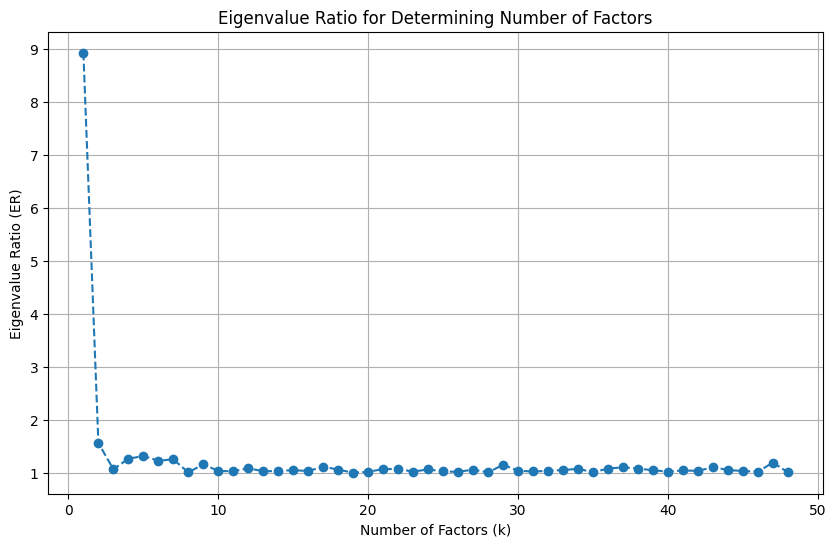

Optimal number of factors: 1


In [122]:
# Step 1: Compute the covariance matrix of the dataset
cov_matrix= np.cov(VWExcessRet, rowvar=False)

# Step 2: Compute the eigenvalues of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Step 3: Sort eigenvalues in descending order
eigenvalues = np.sort(eigenvalues)[::-1]

# Step 4: Calculate the Eigenvalue Ratio (ER) for each k
er_ratios = [eigenvalues[i] / eigenvalues[i + 1] for i in range(len(eigenvalues) - 1)]

# Step 5: Find the optimal number of factors by finding the maximum ratio
optimal_num_factors = np.argmax(er_ratios) + 1

# Step 6: Plot the eigenvalue ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(er_ratios) + 1), er_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Eigenvalue Ratio (ER)')
plt.title('Eigenvalue Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors: {optimal_num_factors}")

##### **Growth Ratio estimator**

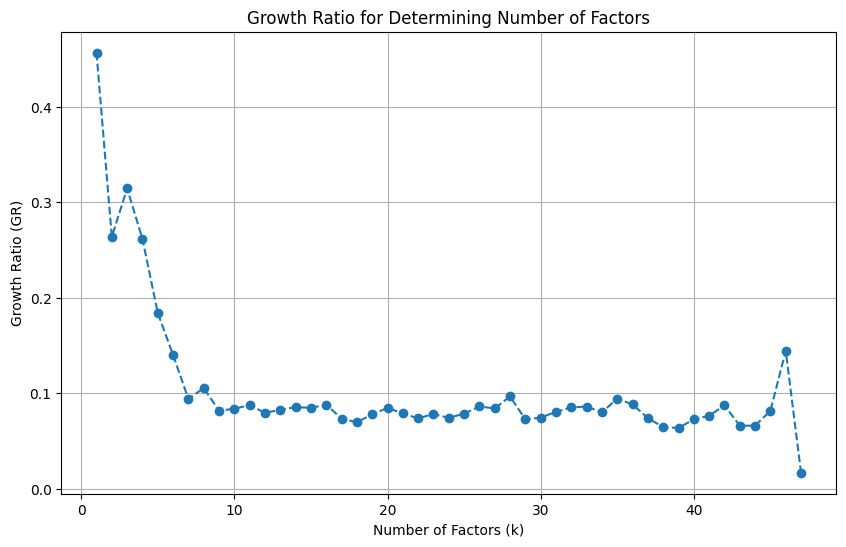

Optimal number of factors (Growth Ratio): 1


In [123]:
# Step 1: Calculate the Growth Ratio (GR) for each k
V = [np.sum(eigenvalues[i+1:]**2) / (len(eigenvalues) - (i + 1)) for i in range(len(eigenvalues) - 1)]
gr_ratios = [np.log(V[k]) - np.log(V[k + 1]) for k in range(len(V) - 1)]

# Step 2: Find the optimal number of factors by finding the maximum growth ratio
optimal_num_factors_gr = np.argmax(gr_ratios) + 1

# Step 3: Plot the growth ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(gr_ratios) + 1), gr_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Growth Ratio (GR)')
plt.title('Growth Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors (Growth Ratio): {optimal_num_factors_gr}")

#### **Number of factors**

In [263]:
# maximum number of factors
rmax = 10

# Preallocate ER and GR
ER = np.zeros((rmax, 1))
GR = np.zeros((rmax, 1))

# Get covariance matrix 
Sigma = np.cov(VWExcessRet, rowvar=False)

# Get eigenvalues of covariance matrix
vals, _ = np.linalg.eigh(Sigma)

# Sort eigenvalues in descending order
vals_sorted = np.sort(vals)[::-1]

# Take top (rmax+1) eigenvalues
DAH = vals_sorted[:rmax+1]

# Compute ER and GR
for j in range(rmax):
    ER[j, 0] = DAH[j] / DAH[j+1]
    GR[j, 0] = np.log(1 + DAH[j]) / np.log(1 + DAH[j+1])

# Find index of maximum GR
max_val = np.max(GR[1:, 0])  # ignoring first row, i.e. index 0
indices = np.where(GR[:, 0] == max_val)[0]  # returns 0-based indices
r = indices[0] + 1 # r = 2

r = 2

##### **Estimation of factors and loadings**

In [264]:
# From previous estimation, we know that the number of factors is 2
r = 2

# Get top eigenvalues and eigenvectors of covariance matrix calculated before
vals, vecs = np.linalg.eigh(Sigma)

# Sort eigenvalues (and corresponding vectors) in descending order
idx = np.argsort(vals)[::-1]
vals = vals[idx]
vecs = vecs[:, idx]

# Extract the top-r eigenvalues/vectors
vals_r = vals[:r]                 
vecs_r = vecs[:, :r] 

# Calculation of factor scores ghat
D_inv_sqrt = np.diag(1.0 / np.sqrt(vals_r))
ghat = (D_inv_sqrt @ vecs_r.T @ VWExcessRet.T).T

# Calculation of loadings Ahat
D_sqrt = np.diag(np.sqrt(vals_r)) 
Ahat = vecs_r @ D_sqrt  

# Reconstructed data
chihat = (Ahat @ ghat.T).T

# Reconstructed data using only 2 factors
chihat1 = (vecs_r @ vecs_r.T @ VWExcessRet.T).T

# Calculation of residuals
ehat = VWExcessRet-chihat

## **EM algorithm**

#### **Initialization of EM parameters**

In [265]:
# EM parameters
kmax = 100
thresh = 1e-6
eps = [0.49, 0.1] 
min_eta = 1e-50

#### **Pre-allocate parameters**

In [399]:
T, N = VWExcessRet.shape

# Create arrays of zeros of correct dimensions to be filled in the estimation phase

Phat       = np.zeros((2, 2, kmax+1))
rhohat     = np.zeros((2*2, kmax+1))   
Bhat       = np.zeros((N, r, 2, kmax+1))
Sigmaehat  = np.zeros((N, N, 2, kmax+1))
etahat     = np.zeros((T, 2, kmax+1))
llik       = np.zeros((kmax+1, 1))    

xit1       = np.zeros((T, 2, kmax+1))
xitt       = np.zeros((T, 2, kmax+1))
xitT       = np.zeros((T, 2, kmax+1))
xitT2      = np.zeros((T, 2*2, kmax+1))  

fhat       = np.zeros((T, r))

temp1      = np.zeros((T, N, 2))
temp2      = np.zeros((T, 2, 2))
temp3      = np.zeros((T,N))

xibar      = np.zeros((2,2))

Define function to reshape an array into a column vector.

In [365]:
def ML_vec(X):
    
    m, n = X.shape
    x = X.reshape(m*n, order='F')
    
    return x

In [401]:
# Initialize parameters

# Assign Bhat
Bhat[:, :, 0, 0] = Ahat
Bhat[:, :, 1, 0] = Ahat

# Assign Sigmaehat
Sigma_e = np.diag(np.diag(np.cov(ehat, rowvar=False)))  # (N,N)
Sigmaehat[:, :, 0, 0] = Sigma_e
Sigmaehat[:, :, 1, 0] = Sigma_e

# Assign first Phat
Phat[:, :, 0] = np.array([
    [0.5 + eps[0],       1 - 0.5 - eps[0]],
    [1 - 0.5 - eps[1],   0.5 + eps[1]]
])

# Assign rhohat
rhohat[:, 0] = ML_vec(Phat[:, :, 0])

xi00 = np.array([1, 0])

In [402]:
# Ensure VWExcessRet is a NumPy array
x = VWExcessRet.to_numpy() if isinstance(VWExcessRet, pd.DataFrame) else VWExcessRet

print(type(x))        # Should print <class 'numpy.ndarray'>
print(x.shape)        # Confirm the dimensions are (T, N)

#ghat = ghat.to_numpy()
print(type(ghat))        # Should print <class 'numpy.ndarray'>
print(ghat.shape)        # Confirm the dimensions are (T, r)

<class 'numpy.ndarray'>
(663, 49)
<class 'numpy.ndarray'>
(663, 2)


In [405]:
# Initialize state
xit1[0, :, 0] = (Phat[:, :, 0].T @ xi00).T

Ec = np.eye(2)

for t in range(T):
    for j in range(2):
        etahat[t, j, 0] = (2 * np.pi) ** (-N / 2) * (np.linalg.det(Sigmaehat[:, :, j, 0])) ** (-1 / 2) * \
            np.exp(-((x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, 0], Bhat[:, :, 1, 0])).T) @ \
            np.linalg.inv(Sigmaehat[:, :, j, 0]) @ \
            (x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, 0], Bhat[:, :, 1, 0])).T).T) / 2)
        if etahat[t, j, 0] == 0:
            etahat[t, j, 0] = min_eta

for k in range(kmax):
    print(f'EM iteration {k}')
    llik[k, 0] = np.sum(np.log(etahat[:, 0, k] + etahat[:, 1, k]))
    print(f'--llik {llik[k, 0]}')

    # E-step
    # Hamilton filter
    for t in range(T):
        xitt[t, :, k] = (etahat[t, :, k] * xit1[t, :, k]) / (np.ones(2) @ (etahat[t, :, k] * xit1[t, :, k]))
        if t < T - 1:
            xit1[t + 1, :, k] = (Phat[:, :, k].T @ xitt[t, :, k]).T

    # Kim smoother
    xitT[T - 1, :, k] = xitt[T - 1, :, k]
    xitT[T - 2, :, k] = ((Phat[:, :, k] @ (xitt[T - 1, :, k] / xit1[T - 1, :, k]).T) * xitt[T - 2, :, k]).T

    revt = np.flipud(np.arange(T - 2))

    for t in range(T - 2):
        xitT[revt[t], :, k] = ((Phat[:, :, k] @ (xitT[revt[t] + 1, :, k] / xit1[revt[t] + 1, :, k]).T) * xitt[revt[t], :, k]).T

    for t in range(1, T):
        xitT2[t, :, k] = np.kron(xitT[t - 1, :, k], xitT[t, :, k])

    if k > 1 and abs(llik[k, 0] - llik[k - 1, 0]) / (0.5 * abs(llik[k, 0] + llik[k - 1, 0])) < thresh:
        kstar = k
        break

    # M-step
    # Estimate parameters
    for j in range(2):
         for t in range(T):
              temp1[t, :, :] = np.outer(x[t, :], ghat[t, :])
              temp2[t, :, :] = np.outer(ghat[t, :], ghat[t, :])

         # Now multiply with xitT[:, j, k] reshaped to (T,1,1)
         sum_temp1 = np.sum(temp1 * xitT[:, j, k, np.newaxis, np.newaxis], axis=0)
         sum_temp2 = np.sum(temp2 * xitT[:, j, k, np.newaxis, np.newaxis], axis=0)
    
         Bhat[:, :, j, k + 1] = sum_temp1 @ np.linalg.inv(sum_temp2)

         for t in range(T):
             temp3[t, :] = (x[t, :] - ghat[t, :] @ Bhat[:, :, j, k + 1].T) ** 2

         Sigmaehat[:, :, j, k + 1] = (np.diag(np.sum(temp3 * xitT[:, j, k, np.newaxis], axis=0)) / np.sum(xitT[:, j, k]))

    # rhohat calculation
    numerator = np.sum(xitT2[:, :, k], axis=0)
    temp = np.sum(xitT[1:T, :, k], axis=0).reshape(-1, 1)  # shape (2,1)
    denominator_2d = np.kron(np.ones((2, 1)), temp)        # shape (4,1)
    denominator = denominator_2d.ravel()                   # shape (4,)

    # Elementwise division => shape (4,)
    rhohat[:, k + 1] = numerator / denominator

    Phat[:, :, k + 1] = np.reshape(rhohat[:, k + 1], (2, 2))

    # New initialization of state
    xit1[0, :, k + 1] = np.mean(xitT[:, :, k], axis=0)

    for t in range(T):
        for j in range(2):
            etahat[t, j, k + 1] = (2 * np.pi) ** (-N / 2) * (np.linalg.det(Sigmaehat[:, :, j, k + 1])) ** (-1 / 2) * \
                np.exp(-((x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, k + 1], Bhat[:, :, 1, k + 1])).T) @ \
                np.linalg.inv(Sigmaehat[:, :, j, k + 1]) @ \
                (x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, k + 1], Bhat[:, :, 1, k + 1])).T).T) / 2)
            if etahat[t, j, k + 1] == 0:
                etahat[t, j, k + 1] = min_eta

if k == kmax:
    print('EM did not converge')
    kstar = kmax

xibar[0, :] = np.mean(xitT[:, :, kstar], axis=0)
xibar[1, :] = [(1 - Phat[1, 1, kstar]), (1 - Phat[0, 0, kstar])] / (2 - Phat[0, 0, kstar] - Phat[1, 1, kstar])

chihat0[:, :, 0] = Bhat[:, :, 0, kstar] * (ghat * np.round(xitT[:, 0, kstar]))[:, np.newaxis]
chihat0[:, :, 1] = Bhat[:, :, 1, kstar] @ (ghat * np.round(xitT[:, 1, kstar]))[:, np.newaxis]

fhat[:, 0] = xitT[:, 0, kstar] * x @ Bhat[:, 0, 0, kstar] / (Bhat[:, 0, 0, kstar].T @ Bhat[:, 0, 0, kstar])
fhat[:, 1] = xitT[:, 1, kstar] * x @ Bhat[:, 1, 1, kstar] / (Bhat[:, 1, 1, kstar].T @ Bhat[:, 1, 1, kstar])

ftilde[:, 0] = xitT[:, 0, kstar] * x @ Bhat[:, 0, 1, kstar] / (Bhat[:, 0, 1, kstar].T @ Bhat[:, 0, 1, kstar])
ftilde[:, 1] = xitT[:, 1, kstar] * x @ Bhat[:, 1, 0, kstar] / (Bhat[:, 1, 0, kstar].T @ Bhat[:, 1, 0, kstar])




EM iteration 0
--llik -89756.87740949457
EM iteration 1
--llik -89756.7935280115
EM iteration 2
--llik -89744.91780112244
EM iteration 3
--llik -89607.36390755765
EM iteration 4
--llik -88808.00606710107
EM iteration 5
--llik -88001.08157984461
EM iteration 6
--llik -87884.89089873387
EM iteration 7
--llik -87857.47478940945
EM iteration 8
--llik -87841.54635838307
EM iteration 9
--llik -87830.68366362143
EM iteration 10
--llik -87823.93465494289
EM iteration 11
--llik -87820.33030766786
EM iteration 12
--llik -87817.97820738281
EM iteration 13
--llik -87816.11307257507
EM iteration 14
--llik -87813.84207492787
EM iteration 15
--llik -87810.81703685556
EM iteration 16
--llik -87809.19873287069
EM iteration 17
--llik -87808.16045463982
EM iteration 18
--llik -87807.30731991853
EM iteration 19
--llik -87806.51102221955
EM iteration 20
--llik -87805.74173350444
EM iteration 21
--llik -87805.00655110346
EM iteration 22
--llik -87804.31543717548
EM iteration 23
--llik -87803.6767589048
EM i

ValueError: operands could not be broadcast together with shapes (663,2) (663,) 

## **Neural Networks** 

### **Autoencoders for factor extraction**

In [1]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 239.4 MB 103 kB/s eta 0:00:01     |████████████████████████████▌   | 213.3 MB 3.0 MB/s eta 0:00:09
     |████████████████████████████████| 1.3 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 5.5 MB 2.7 MB/s eta 0:00:01
     |████████████████████████████████| 396 kB 28.7 MB/s eta 0:00:01
     |████████████████████████████████| 71 kB 1.3 MB/s  eta 0:00:01
     |████████████████████████████████| 5.3 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 9.4 MB/s  eta 0:00:01
     |████████████████████████████████| 417 kB 933 kB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 11.1 MB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 57 kB 12.6 MB/s eta 0:00:01
     |████████████████████████████████| 3.5 MB 24.5 MB/s eta 0:00:01
     |██████████████████████████

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler

In [36]:
# Scale each column to unit variance:
scaler = StandardScaler(with_mean=False)  # <-- no mean subtraction, only std
data_scaled = scaler.fit_transform(VWExcessRet)

In [37]:
# -------------------------------------------------
# Define the autoencoder
# -------------------------------------------------
input_dim = 49
latent_dim = 2  

inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(32, activation='relu')(inputs)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

x = layers.Dense(16, activation='relu')(latent)
x = layers.Dense(32, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='linear')(x)

autoencoder = keras.Model(inputs, outputs, name="autoencoder")
encoder = keras.Model(inputs, latent, name="encoder")

# -------------------------------------------------
# Compile & train
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    data_scaled, data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

# -------------------------------------------------
# Extract the 2-factor representation
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)
print("Shape of extracted factors:", factors_2d.shape)

# factors_2d is now (663, 2)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 1.0594 - val_loss: 1.2080
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9654 - val_loss: 1.0448
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7399 - val_loss: 0.9100
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7006 - val_loss: 0.7370
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5883 - val_loss: 0.5694
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4714 - val_loss: 0.5297
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4246 - val_loss: 0.5188
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4194 - val_loss: 0.5162
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3924 - val_loss: 0.5148
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4065 - val_loss: 0.5105
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3926 - val_loss: 0.5114
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

In [38]:
# ---------------------------------------------------------------------
# Reconstruct data and check reconstruction performance
# ---------------------------------------------------------------------
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Reconstruction MSE:", mse)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Reconstruction MSE: 0.351778822568948


#### **Increase Model Capacity (More Hidden Units)** 

**By adding more (or wider) hidden layers, we give the network more representational power to learn complex patterns.**

In [ ]:
input_dim = 49
latent_dim = 2  

# -------------------------------
# Encoder
# -------------------------------
encoder_inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(64, activation='relu')(encoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -------------------------------
# Decoder
# -------------------------------
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='relu')(decoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
decoder_outputs = layers.Dense(input_dim, activation='linear')(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -------------------------------
# Autoencoder = Encoder + Decoder
# -------------------------------
autoencoder_inputs = keras.Input(shape=(input_dim,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------
# Train
# -------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, # monitor validation loss to ensure we are not overfitting
    verbose=1
)

# -------------------------------
# Extract factors & evaluate
# -------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
mse = np.mean((data_scaled - autoencoder.predict(data_scaled))**2)
print("Reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.9611 - val_loss: 1.1122
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8270 - val_loss: 0.7687
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5395 - val_loss: 0.5362
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4317 - val_loss: 0.5160
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3923 - val_loss: 0.5138
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4048 - val_loss: 0.5096
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3951 - val_loss: 0.5072
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3989 - val_loss: 0.5093
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4015 - val_loss: 0.5026
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3977 - val_loss: 0.5044
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3805 - val_loss: 0.5004
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**Below we implement an even deeper autoencoder architecture that uses layer widths of 128, 64, 32, and 16 in the encoder (and symmetrically in the decoder).**

In [ ]:
input_dim = 49
latent_dim = 2  

# -------------------------------
# Encoder
# -------------------------------
encoder_inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(128, activation='relu')(encoder_inputs)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -------------------------------
# Decoder
# -------------------------------
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='relu')(decoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(128, activation='relu')(x)
decoder_outputs = layers.Dense(input_dim, activation='linear')(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -------------------------------
# Autoencoder = Encoder + Decoder
# -------------------------------
autoencoder_inputs = keras.Input(shape=(input_dim,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile & set up callbacks
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# EarlyStopping callback to prevent overfitting
#early_stopping = keras.callbacks.EarlyStopping(
 #   monitor='val_loss',
  #  patience=10,             # stops if val_loss doesn’t improve for 10 epochs
   # restore_best_weights=True
#)

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  
    #callbacks=[early_stopping],
    verbose=1
)

# -------------------------------------------------
# Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.9130 - val_loss: 1.0056
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7461 - val_loss: 0.6075
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4578 - val_loss: 0.5216
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4001 - val_loss: 0.5150
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4077 - val_loss: 0.5146
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4018 - val_loss: 0.5134
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4062 - val_loss: 0.5118
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3969 - val_loss: 0.5140
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3894 - val_loss: 0.5119
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3912 - val_loss: 0.5135
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3834 - val_loss: 0.5109
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We can see that the autoencoder architecture that uses increasing layer widths always yields slightly better results. Let's try with different activation functions.**

#### **Alternative Activation Functions**

**Until now, we have utlised the most common method called ReLu (Rectified Linear Unit). We will now try different options.**

##### **Leaky ReLu**

**Variation of ReLu that allows a small, non-zero gradient when $x < 0$.**

In [39]:
T, N = VWExcessRet.shape

# -------------------------------------------------
#  Define the autoencoder architecture using LeakyReLU
# -------------------------------------------------
alpha = 0.01  # LeakyReLU negative slope
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))
x = layers.Dense(128)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

latent = layers.Dense(latent_dim, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

decoder_outputs = layers.Dense(N)(x)  # linear output
decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled, 
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# Evaluate
# -------------------------------------------------
# Extract the 2D latent factors
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)

# Check reconstruction MSE on the full dataset
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.8868 - val_loss: 0.8596
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6071 - val_loss: 0.5783
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4512 - val_loss: 0.5137
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3944 - val_loss: 0.5119
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4177 - val_loss: 0.5121
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4085 - val_loss: 0.5090
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3980 - val_loss: 0.5091
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3944 - val_loss: 0.5096
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4062 - val_loss: 0.4994
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3894 - val_loss: 0.4981
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3897 - val_loss: 0.4971
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3539 - val_l

##### **ELU (Exponential Linear Unit)**

**Helps the mean activations closer to zero and can be more robust.**

In [29]:
# -------------------------------------------------
# Define the autoencoder architecture using ELU activation
# -------------------------------------------------
# Keras 'elu' activation defaults alpha=1.0
latent_dim = 2  # number of latent factors

# --- Encoder ---
encoder_inputs = keras.Input(shape=(N,))
x = layers.Dense(128, activation='elu')(encoder_inputs)
x = layers.Dense(64, activation='elu')(x)
x = layers.Dense(32, activation='elu')(x)
x = layers.Dense(16, activation='elu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)
encoder = keras.Model(encoder_inputs, latent, name="encoder")

# --- Decoder ---
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='elu')(decoder_inputs)
x = layers.Dense(32, activation='elu')(x)
x = layers.Dense(64, activation='elu')(x)
x = layers.Dense(128, activation='elu')(x)
decoder_outputs = layers.Dense(N, activation='linear')(x)
decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# --- Combine into Autoencoder ---
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# 3. Compile & EarlyStopping
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# 4. Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
# Extract the 2D latent factors
factors_2d = encoder.predict(data_scaled)  # shape (663, 2)

# Check reconstruction MSE
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.8702 - val_loss: 0.6305
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4824 - val_loss: 0.5572
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4576 - val_loss: 0.5077
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4097 - val_loss: 0.5118
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4009 - val_loss: 0.4938
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3832 - val_loss: 0.4884
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3830 - val_loss: 0.4883
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3809 - val_loss: 0.4858
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3614 - val_loss: 0.4847
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3533 - val_loss: 0.4817
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3528 - val_loss: 0.4866
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We can see that the activation function Leaky ReLu has the better reconstructed MSE**

#### **Other strategies to improve performance**

##### **Regularization**

**Let's implement and autoencoder that utlises layers width of 128, 64, 32, 16 and LeakyReLU activation function and that includes L2 regularization (weight decay) in each layer. L2 regularization penalizes large weights in the network. The penalty is added to the loss function during training, encouraging smaller parameter values and helping to reduce overfitting.**

In [31]:
# -------------------------------------------------
# Define the autoencoder with LeakyReLU & L2 regularization
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 regularization weight
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Latent layer (linear activation by default):
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)

Epoch 1/100


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.8829 - val_loss: 0.8793
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6147 - val_loss: 0.5519
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4163 - val_loss: 0.5237
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3996 - val_loss: 0.5150
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4199 - val_loss: 0.5199
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4170 - val_loss: 0.5160
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3910 - val_loss: 0.5150
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4014 - val_loss: 0.5159
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4017 - val_loss: 0.5093
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4029 - val_loss: 0.5037
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3893 - val_loss: 0.4909
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3858 - val_l

##### **Dropout**

**Dropout randomly drops 20% of the neurons, helping to prevent overfitting.**

In [33]:
# -------------------------------------------------
# 2. Define the autoencoder architecture
#    with LeakyReLU, L2 regularization, and Dropout
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 weight regularization
drop_rate = 0.2  # 20% dropout
latent_dim = 2   # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

# Latent layer (linear activation by default)
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# 3. Compile & EarlyStopping
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# 4. Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  # 10% for validation
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)
print("Latent factors shape:", factors_2d.shape)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1.0385 - val_loss: 1.1872
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9749 - val_loss: 0.9274
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8673 - val_loss: 0.7839
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7034 - val_loss: 0.6985
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5936 - val_loss: 0.6210
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5519 - val_loss: 0.5746
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5683 - val_loss: 0.6334
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5107 - val_loss: 0.5692
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5004 - val_loss: 0.5926
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5087 - val_loss: 0.5653
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5149 - val_loss: 0.5872
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We will settle for the autoencoder with layer widths of 128, 64, 32, 16, Leaky ReLU function and regularization.**

In [40]:
# -------------------------------------------------
# Define the autoencoder with LeakyReLU & L2 regularization
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 regularization weight
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Latent layer (linear activation by default):
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.8547 - val_loss: 0.8463
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5344 - val_loss: 0.5432
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4158 - val_loss: 0.5212
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4161 - val_loss: 0.5175
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3960 - val_loss: 0.5196
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3989 - val_loss: 0.5182
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3997 - val_loss: 0.5166
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3981 - val_loss: 0.5180
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4085 - val_loss: 0.5150
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3859 - val_loss: 0.5128
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4048 - val_loss: 0.5118
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.